# Experiment 4: training budget and price gaps

<div style="border-left:4px solid #2563eb; padding:12px 15px; background:#eff6ff;">
<b>Updated:</b> three paired seeds (0, 1, 2); continuous 10k → 30k → 60k training;
complete forward-linearity tables; mean ± sample SD; configuration-checked caches.
New and changed sections are labelled in blue and commented in code.
</div>

The experiment tests whether longer training or larger absolute price differences
strengthen recovery of the lower-priced original-content factors. All factors change
across views. The four tests are the large-gap control, the training-budget comparison,
larger prices at approximately the same ratio, and a Gaussian reference.

Run Part A, then Part B from top to bottom. The default plan has 18 unique training
trajectories and 24 condition/seed evaluations, totalling 330,000 encoder updates
if no compatible progress exists. Each budget trajectory is trained only once to 60k;
stopping at 30k after 10k adds 20k updates, not 30k.

**Reuse and persistence.** `NG_DIR` matches the updated Experiment 3 checkpoint folder.
Existing states are reused only when the full training configuration matches;
probe changes get a separate evaluation identity. Put both cache and report folders
on persistent storage when using Colab. The old `extension_nongaussian/` JSON scores
contain no model/optimizer state and are not treated as resumable checkpoints.

Changed cells contain no saved experimental results. Run the notebook on your training
device to obtain the new three-seed tables and figures. Historical one-seed report
values should not be relabelled as three-seed averages.


## Part A: shared setup (identical in every notebook)

The cells of this part define the paper's simulation: the latent world, the augmentation at the latent level, the frozen mixing network, the encoder and the contrastive objective. They are copied verbatim from notebook 00, where each step is explained. Run them first; Part B uses `cfg`, `device`, `Settings`, `make_world`, `make_mixing`, `make_encoder` and `contrastive_loss` from here. The demonstration setting is `independent_partial`; each experiment overrides what it changes through `replace(cfg, ...)`.


## 2. Setup and settings

Use a Python 3.10+ notebook kernel. If an import is missing, uncomment the installation line, run it, and restart the kernel if requested. PyTorch can use an available NVIDIA GPU or Apple Silicon GPU; CPU also works. Numerical results can differ across devices and software versions.

In [1]:
import copy
import math
import platform
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import wishart
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

import torch
from torch import nn
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 11, "axes.titlesize": 12, "font.size": 10,
})

versions = {
    "Python": platform.python_version(), "PyTorch": torch.__version__,
    "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.Series(versions, name="Version").to_frame())

,Version
Python,3.13.15
PyTorch,2.11.0+cu130
NumPy,2.1.3
SciPy,1.16.3
scikit-learn,1.6.1


The four named scenarios correspond to the progression in §5.1. Start with `independent_partial`, then change one setting at a time and rerun from this cell.

| Scenario | Chance each style coordinate changes | Dependence within blocks | Style depends on content |
|---|---:|---|---|
| `independent_all` | 1.00 | No | No |
| `independent_partial` | 0.75 | No | No |
| `dependent_blocks` | 0.75 | Yes | No |
| `content_causes_style` | 0.75 | Yes | Yes |

`content_dim` and `style_dim` describe the simulated world. `representation_dim` describes the encoder's output. The standard setting makes the output dimension equal to the content dimension.

`steps` is the number of parameter updates. Every update uses fresh simulated data. `batch_size` controls both the number of positive pairs and the size of the independent negative pool. Each anchor is compared with every item in that pool.

In [2]:
SCENARIO = "independent_partial"

SCENARIOS = {
    "independent_all":      (1.00, False, False),
    "independent_partial":  (0.75, False, False),
    "dependent_blocks":     (0.75, True,  False),
    "content_causes_style": (0.75, True,  True),
}

@dataclass
class Settings:
    seed: int = 7                          # Controls randomness so a run can be repeated.
    content_dim: int = 5                   # Number of true content variables, unchanged across paired views.
    style_dim: int = 5                     # Number of true style variables, which may change across views.
    representation_dim: int = 5            # Number of encoder outputs; equals content_dim.
    style_change_prob: float = 0.75        # Probability that each style coordinate is selected for change ("Biased Coin")
    statistical_dependence: bool = False   # If True, allow correlations within content, style noise, and augmentation noise.
    content_dependent_style: bool = False  # If True, generate style as s = a + Bc + noise.
    marginal_std: float = 1.0              # Standard deviation of content and residual style noise when dependence is off.
    style_noise_std: float = 1.0           # Standard deviation of noise added to selected style coordinates when dependence is off.
    mixing_layers: int = 3                 # Number of linear layers in the fixed latent-to-observation network.
    condition_pool: int = 25000            # Number of random matrices used to estimate a conditioning threshold.
    condition_quantile: float = 0.001      # Set the threshold using roughly the best-conditioned 0.1% of those matrices.
    learning_rate: float = 1e-4            # Controls the size of the encoder's parameter updates during training.
    temperature: float = 1.0               # Scales distances in the contrastive loss; smaller values sharpen comparisons.
    batch_size: int = 1024                  # Positive pairs per update; also the number of independent negative examples.
    steps: int = 10000                      # Total number of encoder parameter updates.
    log_every: int = 200                   # Print training progress every this many updates.
    probe_train_size: int = 3000            # Examples used to fit evaluation models that predict latents from representations.
    probe_test_size: int = 5000            # Separate examples used to test those evaluation models.
    device: str = "auto"                   # Automatically choose CUDA, then MPS, then CPU; can also set one explicitly.

cfg = Settings()
(cfg.style_change_prob, cfg.statistical_dependence,
 cfg.content_dependent_style) = SCENARIOS[SCENARIO]

# Original script's training scale (not enabled for this demonstration):
# cfg.batch_size = 6144
# cfg.steps = 100001
# The original nonlinear evaluation fits probes on 5 * 4096 examples and
# evaluates on 10 fresh batches of 4096. Kernel regression at that size is costly.

assert min(cfg.content_dim, cfg.style_dim, cfg.representation_dim) >= 1
assert 0 <= cfg.style_change_prob <= 1
assert min(cfg.marginal_std, cfg.style_noise_std, cfg.temperature) > 0
assert cfg.steps > 0 and cfg.batch_size > 1

if cfg.device != "auto":
    device = torch.device(cfg.device)
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(cfg.seed)
torch.set_num_threads(2)  # Avoid oversubscribing CPU cores in small examples.
latent_dim = cfg.content_dim + cfg.style_dim
print(f"Scenario: {SCENARIO}; device: {device}")
display(pd.Series(asdict(cfg), name="Setting").to_frame())

Scenario: independent_partial; device: cuda


,Setting
seed,7
content_dim,5
style_dim,5
representation_dim,5
style_change_prob,0.75
statistical_dependence,False
content_dependent_style,False
marginal_std,1.0
style_noise_std,1.0
mixing_layers,3


## 3. Build the latent world

We first draw content, then draw style:
$
c\sim N(0,\Sigma_c),\qquad
s=a+Bc+\varepsilon_s,\qquad
\varepsilon_s\sim N(0,\Sigma_s),
$
with independent content and residual draws.

If `statistical_dependence=False`, the covariance matrices are diagonal. If it is `True`, we generate covariance matrices that allow coordinates within each block to be correlated. A Wishart draw is simply a convenient way to generate a positive definite covariance matrix.

If `content_dependent_style=False`, we set $(a=0)$ and $(B=0)$. Otherwise, $(a+Bc)$ makes the distribution of style depend on content. This implements the paper's example of content influencing style.

The covariance matrices and $(a,B)$ are drawn once and then kept fixed. We repeatedly sample new people or objects from this same artificial world.

In [3]:
def make_world(settings):
    """Create fixed parameters of the data distribution on the CPU."""
    rng = np.random.default_rng(settings.seed)
    nc, ns = settings.content_dim, settings.style_dim

    def covariance(dim, std):
        if settings.statistical_dependence:
            # Match the intended Wishart construction in the original experiment.
            matrix = np.atleast_2d(wishart.rvs(df=dim, scale=np.eye(dim), random_state=rng))
        else:
            matrix = (std ** 2) * np.eye(dim)
        return torch.tensor(matrix, dtype=torch.float64)

    Sigma_c = covariance(nc, settings.marginal_std)
    Sigma_s = covariance(ns, settings.marginal_std)
    Sigma_aug = covariance(ns, settings.style_noise_std)
    # As in upstream spaces.py, explicit covariances supersede the std arguments.
    a = torch.zeros(ns)
    B = torch.zeros(ns, nc)
    if settings.content_dependent_style:
        a = torch.tensor(rng.standard_normal(ns), dtype=torch.float32)
        B = torch.tensor(rng.standard_normal((ns, nc)), dtype=torch.float32)
    return {
        "L_c": torch.linalg.cholesky(Sigma_c).float(),
        "L_s": torch.linalg.cholesky(Sigma_s).float(),
        "L_aug": torch.linalg.cholesky(Sigma_aug).float(),
        "a": a, "B": B,
    }

world = make_world(cfg)

def sample_latents(size, generator):
    """Draw z=(c,s). Latent values are used by the simulator and evaluator."""
    c = torch.randn(size, cfg.content_dim, generator=generator) @ world["L_c"].T
    eps_s = torch.randn(size, cfg.style_dim, generator=generator) @ world["L_s"].T
    s = world["a"] + c @ world["B"].T + eps_s
    return torch.cat([c, s], dim=1)

display(pd.DataFrame({
    "block": ["content", "style residual", "augmentation noise"],
    "dimension": [cfg.content_dim, cfg.style_dim, cfg.style_dim],
    "covariance": ["L_c @ L_c.T", "L_s @ L_s.T", "L_aug @ L_aug.T"],
}))

,block,dimension,covariance
0,content,5,L_c @ L_c.T
1,style residual,5,L_s @ L_s.T
2,augmentation noise,5,L_aug @ L_aug.T


For each original example, choose which style coordinates change using independent Bernoulli draws:
$
M_j\sim\mathrm{Bernoulli}(p),\qquad
\widetilde s=s+M\odot\eta,\qquad
\eta\sim N(0,\Sigma_{\mathrm{aug}}).
$
The symbol $(\odot)$ means coordinatewise multiplication. Content is copied exactly. A style coordinate whose mask equals zero is also copied exactly. The selected subset \(A\) is the set of coordinates whose masks equal one.

We additionally generate independent examples for the negative pool. They come from the same original latent distribution; they are not paired with the anchors.

When $(p>0)$ and the noise covariance is positive definite, each style coordinate has a chance to vary locally. Setting $(p=0)$ removes this property and changes the identification problem.

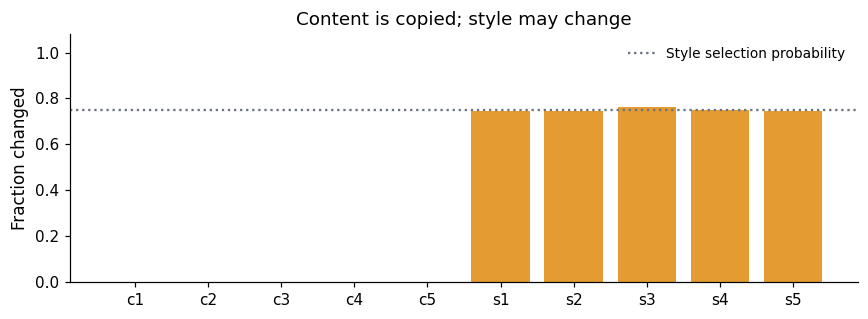

In [4]:
def augment_latents(z, generator):
    nc = cfg.content_dim
    style = z[:, nc:]
    mask = (torch.rand(style.shape, generator=generator) < cfg.style_change_prob)
    noise = torch.randn(style.shape, generator=generator) @ world["L_aug"].T
    changed_style = style + mask * noise
    return torch.cat([z[:, :nc], changed_style], dim=1)

def sample_triplet(size, generator):
    z = sample_latents(size, generator)
    z_negative = sample_latents(size, generator)
    z_augmented = augment_latents(z, generator)
    return z, z_augmented, z_negative

# A separate random stream keeps this inspection from changing training data.
inspection_rng = torch.Generator().manual_seed(cfg.seed + 10)
z_check, z_aug_check, _ = sample_triplet(5000, inspection_rng)
assert torch.equal(z_check[:, :cfg.content_dim], z_aug_check[:, :cfg.content_dim])
change_rates = (z_check != z_aug_check).float().mean(dim=0).numpy()
names = ([f"c{i+1}" for i in range(cfg.content_dim)] +
         [f"s{i+1}" for i in range(cfg.style_dim)])

fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#227c9d"] * cfg.content_dim + ["#e49b32"] * cfg.style_dim
ax.bar(names, change_rates, color=colors)
ax.axhline(cfg.style_change_prob, color="#6b7280", linestyle=":", label="Style selection probability")
ax.set(ylim=(0, 1.08), ylabel="Fraction changed", title="Content is copied; style may change")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Hide the latents behind a fixed mixing network

The mixing network converts $(z)$ into $(x)$. It has square, invertible weight matrices and LeakyReLU activations with a nonzero negative slope. Its input and output both have dimension $(n_c+n_s)$, as in this particular synthetic experiment.

The condition number measures how unevenly a matrix stretches different directions. The code samples candidate matrices and keeps well-conditioned ones. This reduces severe numerical distortion; it is not a training step.

The mixing parameters are frozen. Only the encoder will be trained. LeakyReLU is invertible here but has a kink at zero, so this implementation is not literally smooth everywhere as required by the theorems.

In [5]:
def make_mixing(settings):
    """Adapt the upstream well-conditioned, square mixing MLP."""
    n = settings.content_dim + settings.style_dim
    rng = np.random.default_rng(settings.seed + 100)

    def candidate():
        matrix = rng.uniform(-1, 1, size=(n, n))
        return matrix / np.linalg.norm(matrix, axis=0, keepdims=True)

    conditions = np.array([
        np.linalg.cond(candidate()) for _ in range(settings.condition_pool)
    ])
    threshold = np.sort(conditions)[int(settings.condition_pool * settings.condition_quantile)]
    modules, accepted_conditions = [], []
    for layer in range(settings.mixing_layers):
        matrix = candidate()
        while np.linalg.cond(matrix) > threshold:
            matrix = candidate()
        linear = nn.Linear(n, n, bias=False)
        with torch.no_grad():
            linear.weight.copy_(torch.tensor(matrix, dtype=torch.float32))
        modules.append(linear)
        accepted_conditions.append(np.linalg.cond(matrix))
        if layer < settings.mixing_layers - 1:
            modules.append(nn.LeakyReLU(negative_slope=0.2))
    network = nn.Sequential(*modules).to(device)
    network.requires_grad_(False)
    network.eval()
    return network, accepted_conditions

mixing, condition_numbers = make_mixing(cfg)
print("Mixing layer condition numbers:", np.round(condition_numbers, 2))
print("Mixing parameters trainable:", any(p.requires_grad for p in mixing.parameters()))

with torch.no_grad():
    x_check = mixing(z_check[:5].to(device))
print("Latent shape:", tuple(z_check[:5].shape))
print("Observation shape:", tuple(x_check.shape))

Mixing layer condition numbers: [4.56 4.26 4.91]
Mixing parameters trainable: False
Latent shape: (5, 10)
Observation shape: (5, 10)


The encoder receives the mixed observation and outputs \(k\) numbers, where `representation_dim = k`. We preserve the original script's hidden-layer widths and activations.

With the default dimensions, the learned mapping is $(g:\mathbb R^{10}\to\mathbb R^5)$. It cannot invert the full observation. The desired result is an invertible representation of the five-dimensional content block after discarding additional style variation.

In [6]:
def make_encoder(settings):
    n = settings.content_dim + settings.style_dim
    # Same hidden widths as main_mlp.py; final layer has no activation.
    widths = [n, n * 10, n * 50, n * 50, n * 50, n * 50, n * 10,
              settings.representation_dim]
    modules = []
    for i, (n_in, n_out) in enumerate(zip(widths[:-1], widths[1:])):
        modules.append(nn.Linear(n_in, n_out))
        if i < len(widths) - 2:
            modules.append(nn.LeakyReLU(negative_slope=0.01))
    return nn.Sequential(*modules).to(device)

torch.manual_seed(cfg.seed + 200)
encoder = make_encoder(cfg)
initial_encoder = copy.deepcopy(encoder).eval()
print(encoder)
print("Trainable encoder parameters:", sum(p.numel() for p in encoder.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=100, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=100, out_features=500, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=500, out_features=500, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=500, out_features=500, bias=True)
  (7): LeakyReLU(negative_slope=0.01)
  (8): Linear(in_features=500, out_features=500, bias=True)
  (9): LeakyReLU(negative_slope=0.01)
  (10): Linear(in_features=500, out_features=100, bias=True)
  (11): LeakyReLU(negative_slope=0.01)
  (12): Linear(in_features=100, out_features=5, bias=True)
)
Trainable encoder parameters: 853705


## 5. The contrastive objective

Let $(u_i=g(x_i))$, $(v_i=g(\widetilde x_i))$, and $(w_j=g(x_j^-))$. The first two form a positive pair. The $(w_j)$'s are encoded observations from the independent negative pool.

For the original loss's default settings, define
$
d_i^+=\|u_i-v_i\|^2,\qquad d_{ij}^-=\|u_i-w_j\|^2.
$
With batch size $(m)$ and temperature $(\tau)$, the loss is
$
\frac1m\sum_i\left[
\frac{d_i^+}{\tau}
+\log\left\{\frac{e^{-d_i^+/\tau}+\sum_{j=1}^m e^{-d_{ij}^-/\tau}}{m+1}\right\}
\right].
$

The first term encourages paired representations to agree. The second makes mapping everything to the same point unattractive: independent examples can instead be separated while positive pairs remain close. Both effects depend on the same learned representation.

This is the squared-distance, InfoNCE-style objective used in the synthetic script. The denominator uses a mean rather than a sum, changing the loss by a constant for fixed batch size. Negative loss values are therefore normal.

We do not calculate differential entropy directly. Theorem 4.4 studies exact population alignment plus entropy on a bounded output domain; this code uses a finite batch contrastive surrogate and unconstrained outputs. Its numerical behavior is evidence about the method, not a direct execution of that theorem's assumptions.

In [7]:
def contrastive_loss(anchor, positive, negative, temperature=1.0):
    """Same objective as LpSimCLRLoss at its default p=2, alpha=0.5."""
    positive_distance = (anchor - positive).square().sum(dim=1)
    # Algebraically equal to all pairwise squared differences, using less memory.
    negative_distance = (
        anchor.square().sum(dim=1, keepdim=True)
        + negative.square().sum(dim=1).unsqueeze(0)
        - 2 * anchor @ negative.T
    ).clamp_min(0)
    all_distances = torch.cat([negative_distance, positive_distance[:, None]], dim=1)
    alignment = positive_distance / temperature
    contrast = torch.logsumexp(-all_distances / temperature, dim=1)
    contrast = contrast - math.log(all_distances.shape[1])
    loss = (alignment + contrast).mean()
    return loss, alignment.mean().detach(), contrast.mean().detach()

zero = torch.zeros(8, cfg.representation_dim, device=device)
collapsed_loss, _, _ = contrastive_loss(zero, zero, zero, cfg.temperature)
print(f"Loss of a constant representation: {collapsed_loss.item():.3f}")

Loss of a constant representation: 0.000


## Part B: Experiment 4


## <span style="color:#2563eb">CHANGED: paired three-seed design</span>
Edit `FU_SEEDS` and `RUN_TESTS` here. The value-dependent case has been removed
from the driver. All original-content and style coordinates receive independent
additive changes; `SCENARIO` in Part A does not select this experiment's sampler.


In [8]:
# CHANGED [1]: three paired seeds, four report tests, and explicit absolute budgets.
import contextlib
import hashlib
import json
import random
from dataclasses import asdict, replace
import sklearn

FU_SEEDS = [0, 1, 2]
RUN_TESTS = {'control', 'budget', 'level', 'gaussian'}
FU_BASE_UPDATES = 10000
BUDGETS = [10000, 30000, 60000]
# Standard deviations; their squares are nominal coordinate prices.
# The original (0.10, 0.30) point is reused as the level plot's baseline.
LEVELS = [(0.20, 0.60), (0.33, 1.00)]

# CHANGED: use a persistent path on Colab. This training-cache path and the
# numerical train/probe versions match the updated Experiment 3 notebook,
# allowing reuse ONLY when the complete configurations agree.
NG_DIR = Path('extension_nongaussian_budget_v1')
FU_DIR = Path('extension_finite_budget_v1')
NG_DIR.mkdir(parents=True, exist_ok=True)
FU_DIR.mkdir(parents=True, exist_ok=True)
NG_SAVE_EVERY = 5000
NG_EVALUATE_LINEARITY = True
NG_SAVE_ENCODED_ARRAYS = True
NG_TRAIN_VERSION = 'exp3_checkpoint_train_v1'
NG_PROBE_VERSION = 'exp3_probe_v1'
FU_PLAN_VERSION = 'exp4_three_seed_plan_v1'
# Bump train/probe versions if their numerical algorithms are changed.

NG_CONTENT_STD = 0.10
NG_S1_STD = 0.30
NG_OTHER_STD = 1.00
NG_CONTENT_MARGINAL = 'uniform'
NG_HETERO = 0.0  # compatibility with Experiment 3; always zero in this report
FU_DEFAULT_KNOBS = dict(NG_CONTENT_STD=0.10, NG_S1_STD=0.30,
                        NG_OTHER_STD=1.00, NG_CONTENT_MARGINAL='uniform',
                        NG_HETERO=0.0)

NC, NS = cfg.content_dim, cfg.style_dim
N = NC + NS
COORDS = [f'c{i+1}' for i in range(NC)] + [f's{i+1}' for i in range(NS)]
base_ng = replace(cfg, style_change_prob=1.0, statistical_dependence=False,
                  content_dependent_style=False, steps=FU_BASE_UPDATES)
assert NS >= 2 and NC + 1 <= N
assert FU_SEEDS and len(set(FU_SEEDS)) == len(FU_SEEDS)
assert all(isinstance(seed, int) and seed >= 0 for seed in FU_SEEDS)
assert RUN_TESTS and RUN_TESTS <= {'control', 'budget', 'level', 'gaussian'}
assert BUDGETS == sorted(set(BUDGETS)) and BUDGETS[0] == FU_BASE_UPDATES
assert FU_BASE_UPDATES > 0 and NG_SAVE_EVERY > 0
assert all(c > 0 and s > 0 for c, s in LEVELS)
assert len(set(LEVELS)) == len(LEVELS)
assert len({c for c, _ in LEVELS}) == len(LEVELS), 'Level content prices must be distinct.'
assert all(not math.isclose(c, .10) for c, _ in LEVELS), 'The baseline is added separately.'
print('Device:', device)
print('Paired seeds:', FU_SEEDS, '| enabled tests:', sorted(RUN_TESTS))
print('Training cache:', NG_DIR.resolve())
print('Experiment 4 reports:', FU_DIR.resolve())
print('Legacy JSON-only caches in extension_nongaussian/ are not imported.')


Device: cuda
Paired seeds: [0, 1, 2] | enabled tests: ['budget', 'control', 'gaussian', 'level']
Training cache: /content/extension_nongaussian_budget_v1
Experiment 4 reports: /content/extension_finite_budget_v1
Legacy JSON-only caches in extension_nongaussian/ are not imported.


### Sampling and probes (unchanged numerical algorithms)
The non-Gaussian setting uses independent unit-variance uniform original-content
factors and Laplace style factors, with independent additive Laplace perturbations.
The Gaussian reference replaces both the latent and perturbation distributions.
Recovery probes predict latents from representations; forward linearity fits
predict representations from latents. A small forward gap is informative about
approximate linearity only when the forward linear fit itself has high R².


In [9]:
def laplace(shape, gen, std):
    """Laplace noise with the requested std, as the difference of two exponentials.
    Var(Laplace(b)) = 2 b^2, so b = std / sqrt(2). rand is in [0, 1), so 1 - rand is in
    (0, 1] and log1p(-rand) never sees zero (the earlier inverse-CDF version could)."""
    b = std / np.sqrt(2.0)
    e1 = -torch.log1p(-torch.rand(shape, generator=gen))
    e2 = -torch.log1p(-torch.rand(shape, generator=gen))
    return b * (e1 - e2)


def ng_noise(shape, gen, std, world):
    if world == "gaussian":
        return torch.randn(shape, generator=gen) * std
    return laplace(shape, gen, std)


def ng_draw_z(size, gen, world):
    """Latents with unit variance. Gaussian world: all N(0,1). Non-Gaussian world: content
    uniform on (-sqrt3, sqrt3) or Laplace, style Laplace."""
    if world == "gaussian":
        return torch.randn(size, N, generator=gen)
    if NG_CONTENT_MARGINAL == "laplace":
        c = laplace((size, NC), gen, 1.0)
    else:
        c = (torch.rand(size, NC, generator=gen) * 2 - 1) * np.sqrt(3.0)
    s = laplace((size, NS), gen, 1.0)
    return torch.cat([c, s], dim=1)


def ng_change_std():
    v = np.full(N, NG_OTHER_STD, dtype=np.float32)
    v[:NC] = NG_CONTENT_STD
    v[NC] = NG_S1_STD
    return torch.as_tensor(v)


def ng_perturb(z, gen, world):
    """Second view: every coordinate moves by noise of the chosen std (optionally value-dependent)."""
    scale = ng_change_std() * (1.0 + NG_HETERO * z.abs())
    return z + ng_noise(z.shape, gen, 1.0, world) * scale


def ng_triplet(size, gen, world):
    z = ng_draw_z(size, gen, world)
    z_neg = ng_draw_z(size, gen, world)
    return z, ng_perturb(z, gen, world), z_neg


def ng_prices(world, n=50000):
    z, z_aug, _ = ng_triplet(n, torch.Generator().manual_seed(12345), world)
    return ((z_aug - z).var(dim=0) / z.var(dim=0)).numpy()





KRR_GRID = {"kernelridge__alpha": [1.0, 0.1, 0.01, 0.001],
            "kernelridge__gamma": [float(g) for g in np.logspace(-2, 2, 4)]}


def kernel_fit(X_tr, Y_tr):
    search = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel="rbf")),
                          KRR_GRID, scoring="r2", cv=3, n_jobs=1)
    with threadpool_limits(limits=2):
        search.fit(X_tr, Y_tr)
    return search


def ng_probe(X_tr, Y_tr, X_te, Y_te):
    """Latents from the representation: held-out R^2 per coordinate, linear and kernel probes."""
    lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, Y_tr)
    lin_r2 = r2_score(Y_te, lin.predict(X_te), multioutput="raw_values")
    pred = np.zeros_like(Y_te)
    for cols in (slice(0, NC), slice(NC, None)):
        pred[:, cols] = kernel_fit(X_tr, Y_tr[:, cols]).predict(X_te)
    return lin_r2, r2_score(Y_te, pred, multioutput="raw_values")


def linearity_of_h(X, Z):
    """How linear is the learned map h: z -> representation?

    Fit the representation X from the latents Z with a linear model and with a kernel
    model on half the data, score on the other half. Returns per-output R^2 for both.
    Approximate linearity needs high linear-fit R² as well as a small kernel-minus-linear gap.
    This is the forward direction, h itself, unlike the probes, which fit its inverse.
    """
    n = len(Z) // 2
    lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Z[:n], X[:n])
    lin_r2 = r2_score(X[n:], lin.predict(Z[n:]), multioutput="raw_values")
    ker_r2 = r2_score(X[n:], kernel_fit(Z[:n], X[:n]).predict(Z[n:]), multioutput="raw_values")
    return lin_r2, ker_r2


### <span style="color:#2563eb">ADDED: configuration-aware checkpoint and evaluation caches</span>
Training identity includes seed, dimension, latent and augmentation settings,
learning rate, batch size, temperature, architecture settings and numerical versions.
The stopping budget is excluded so a trajectory can be extended. Probe settings
have a separate identity, so a probe change does not force neural retraining.
These helpers are compatible with the revised Experiment 3 engine.


In [10]:
# ADDED [2]: versioned training identity excludes stopping budget and probe settings.
def ng_digest(config):
    encoded = json.dumps(config, sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(encoded.encode()).hexdigest()[:16]


def ng_training_configuration(settings, world):
    training_settings = asdict(settings)
    for key in ['steps', 'probe_train_size', 'probe_test_size', 'log_every', 'device']:
        training_settings.pop(key, None)
    return {
        'version': NG_TRAIN_VERSION, 'world': world, 'settings': training_settings,
        'original_content_marginal': NG_CONTENT_MARGINAL,
        'content_std': float(NG_CONTENT_STD), 's1_std': float(NG_S1_STD),
        'other_style_std': float(NG_OTHER_STD), 'heterogeneity': float(NG_HETERO),
        'sampler': 'independent_coordinates_original_marginal_negatives',
        'encoder_widths': [N, N * 10, N * 50, N * 50, N * 50, N * 50, N * 10,
                           settings.representation_dim],
        'encoder_negative_slope': 0.01, 'mixing_negative_slope': 0.2,
        'mixing_seed': settings.seed + 100, 'encoder_seed': settings.seed + 200,
        'training_data_seed': settings.seed + 300, 'runtime_device': str(device),
        'torch_version': str(torch.__version__), 'numpy_version': str(np.__version__),
    }


def ng_evaluation_configuration(settings):
    return {
        'version': NG_PROBE_VERSION, 'probe_train_size': settings.probe_train_size,
        'probe_test_size': settings.probe_test_size, 'probe_grid': KRR_GRID,
        'probe_train_seed': settings.seed + 400, 'probe_test_seed': settings.seed + 500,
        'forward_linearity': bool(NG_EVALUATE_LINEARITY),
        'forward_split': 'first_half_of_probe_test_for_fit_second_half_for_score',
        'save_encoded_arrays': bool(NG_SAVE_ENCODED_ARRAYS),
        'sklearn_version': str(sklearn.__version__),
    }


def ng_atomic_json(path, value):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)


def ng_cpu_state(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: ng_cpu_state(item) for key, item in value.items()}
    if isinstance(value, list):
        return [ng_cpu_state(item) for item in value]
    if isinstance(value, tuple):
        return tuple(ng_cpu_state(item) for item in value)
    return value


def ng_save_checkpoint(path, net, mix, opt, gen, step, config, history):
    payload = {
        'configuration': config, 'step': int(step),
        'encoder_state': ng_cpu_state(net.state_dict()),
        'mixing_state': ng_cpu_state(mix.state_dict()),
        'optimizer_state': ng_cpu_state(opt.state_dict()),
        'training_generator_state': gen.get_state().clone(),
        'torch_cpu_rng_state': torch.get_rng_state().clone(),
        'torch_cuda_rng_state': (torch.cuda.get_rng_state(device).cpu()
                                 if device.type == 'cuda' else None),
        'numpy_rng_state': np.random.get_state(), 'python_rng_state': random.getstate(),
        'history': list(history),
    }
    temporary = path.with_name(path.name + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def ng_load_checkpoint(path, net, mix, opt, gen, config):
    # These are our own checkpoints, including optimizer and RNG metadata.
    payload = torch.load(path, map_location='cpu', weights_only=False)
    if payload.get('configuration') != config:
        raise RuntimeError(f'Checkpoint configuration mismatch: {path}')
    net.load_state_dict(payload['encoder_state'])
    mix.load_state_dict(payload['mixing_state'])
    opt.load_state_dict(payload['optimizer_state'])
    for state in opt.state.values():
        for key, value in state.items():
            if torch.is_tensor(value) and key != 'step':
                state[key] = value.to(device)
    gen.set_state(payload['training_generator_state'].cpu())
    torch.set_rng_state(payload['torch_cpu_rng_state'].cpu())
    if device.type == 'cuda' and payload.get('torch_cuda_rng_state') is not None:
        torch.cuda.set_rng_state(payload['torch_cuda_rng_state'].cpu(), device=device)
    np.random.set_state(payload['numpy_rng_state'])
    random.setstate(payload['python_rng_state'])
    return int(payload['step']), list(payload.get('history', []))


def ng_checkpoint_before(folder, target):
    # A later model must never be evaluated under an earlier budget label.
    candidates = []
    for path in folder.glob('checkpoint_step_*.pt'):
        try:
            step = int(path.stem.rsplit('_', 1)[1])
        except ValueError:
            continue
        if step <= target:
            candidates.append((step, path))
    latest = folder / 'checkpoint_latest.pt'
    if latest.exists():
        metadata = torch.load(latest, map_location='cpu', weights_only=False)
        step = int(metadata['step'])
        if step <= target:
            candidates.append((step, latest))
    return max(candidates, key=lambda item: item[0])[1] if candidates else None


In [11]:
# ADDED [3]: fixed held-out probe draws across budgets; separate evaluation cache.
def ng_evaluate(net, mix, settings, world, budget, folder, training_config):
    evaluation_config = ng_evaluation_configuration(settings)
    identity = ng_digest(evaluation_config)
    path = folder / f'evaluation_step_{budget}_{identity}.json'
    arrays_path = folder / f'evaluation_step_{budget}_{identity}.npz'
    if path.exists() and (not NG_SAVE_ENCODED_ARRAYS or arrays_path.exists()):
        cached = json.loads(path.read_text())
        if (cached.get('_training_configuration') != training_config
                or cached.get('_evaluation_configuration') != evaluation_config):
            raise RuntimeError(f'Evaluation cache mismatch: {path}')
        print(f'Verified evaluation: {world}, d={settings.representation_dim}, '
              f'seed={settings.seed}, updates={budget:,}.')
        return cached
    net.eval()
    t0 = time.perf_counter()

    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu()
                          for chunk in z.split(512)]).numpy().astype(np.float64)

    z_tr = ng_draw_z(settings.probe_train_size,
                     torch.Generator().manual_seed(settings.seed + 400), world)
    z_te = ng_draw_z(settings.probe_test_size,
                     torch.Generator().manual_seed(settings.seed + 500), world)
    X_tr, X_te = encode(z_tr), encode(z_te)
    Z_tr, Z_te = z_tr.numpy().astype(np.float64), z_te.numpy().astype(np.float64)
    if NG_SAVE_ENCODED_ARRAYS:
        temporary = arrays_path.with_name(arrays_path.name + '.tmp')
        with temporary.open('wb') as handle:
            np.savez_compressed(handle, X_train=X_tr, X_test=X_te,
                                Z_train=Z_tr, Z_test=Z_te)
        temporary.replace(arrays_path)
    lin, nonlin = ng_probe(X_tr, Z_tr, X_te, Z_te)
    h_lin, h_ker = None, None
    if NG_EVALUATE_LINEARITY:
        h_lin, h_ker = linearity_of_h(X_te, Z_te)
    result = {
        'world': world, 'rep_dim': settings.representation_dim, 'seed': settings.seed,
        'updates': int(budget), 'steps': int(budget),
        'content_nonlinear': float(nonlin[:NC].mean()),
        'style_nonlinear': float(nonlin[NC:].mean()),
        'other_style_nonlinear': float(nonlin[NC + 1:].mean()) if NS > 1 else None,
        'content_linear': float(lin[:NC].mean()),
        'style_linear': float(lin[NC:].mean()),
        'h_linear_r2': float(h_lin.mean()) if h_lin is not None else None,
        'h_kernel_r2': float(h_ker.mean()) if h_ker is not None else None,
        'h_gap': float(h_ker.mean() - h_lin.mean()) if h_lin is not None else None,
        'evaluation_seconds': time.perf_counter() - t0,
        'checkpoint': str(folder / f'checkpoint_step_{budget}.pt'),
        'encoded_arrays': str(arrays_path) if NG_SAVE_ENCODED_ARRAYS else None,
        '_training_configuration': training_config,
        '_evaluation_configuration': evaluation_config,
    }
    result.update({f'nonlin_{name}': float(value) for name, value in zip(COORDS, nonlin)})
    result.update({f'lin_{name}': float(value) for name, value in zip(COORDS, lin)})
    if h_lin is not None:
        result.update({f'h_lin_out{i+1}': float(value) for i, value in enumerate(h_lin)})
        result.update({f'h_ker_out{i+1}': float(value) for i, value in enumerate(h_ker)})
    ng_atomic_json(path, result)
    return result


### <span style="color:#2563eb">CHANGED: resume one trajectory through all requested budgets</span>
Checkpoints retain encoder and mixing weights, Adam state, completed updates,
the training-data generator, and CPU/current-CUDA random states. Every requested
budget is saved before probing. A later model is never scored under an earlier
budget label. Reproducibility across different hardware/backends is not guaranteed.
Longer training also uses more fresh simulated pairs.


In [12]:
# ADDED [4]: continuous training to absolute update budgets, with resumable Adam/RNG state.
def ng_train_to_budgets(world, rep_dim, seed, budgets):
    budgets = sorted(set(int(value) for value in budgets))
    if not budgets or budgets[0] <= 0:
        raise ValueError('Training budgets must be positive.')
    settings = replace(base_ng, seed=int(seed), representation_dim=int(rep_dim))
    config = ng_training_configuration(settings, world)
    folder = NG_DIR / 'checkpoints' / f'{world}_d{rep_dim}_seed{seed}_{ng_digest(config)}'
    folder.mkdir(parents=True, exist_ok=True)
    config_path = folder / 'training_configuration.json'
    if config_path.exists() and json.loads(config_path.read_text()) != config:
        raise RuntimeError(f'Training cache mismatch: {folder}')
    ng_atomic_json(config_path, config)

    mix, _ = make_mixing(settings)
    torch.manual_seed(settings.seed + 200)
    net = make_encoder(settings)
    opt = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    gen = torch.Generator().manual_seed(settings.seed + 300)
    step, history, results = 0, [], []
    latest_path = folder / 'checkpoint_latest.pt'
    latest_saved_step = (int(torch.load(latest_path, map_location='cpu', weights_only=False)['step'])
                         if latest_path.exists() else -1)

    def save_latest():
        # Re-evaluating 10k must not overwrite useful later progress (e.g. an interrupted 35k run).
        nonlocal latest_saved_step
        if step >= latest_saved_step:
            ng_save_checkpoint(latest_path, net, mix, opt, gen, step, config, history)
            latest_saved_step = step

    for budget in budgets:
        candidate = ng_checkpoint_before(folder, budget)
        if candidate is not None:
            candidate_step = int(torch.load(candidate, map_location='cpu', weights_only=False)['step'])
            if candidate_step > step:
                step, history = ng_load_checkpoint(candidate, net, mix, opt, gen, config)
                print(f'Resumed {world}, d={rep_dim}, seed={seed} at {step:,} updates.')
        if step > budget:
            raise RuntimeError('Checkpoint step exceeds the requested evaluation budget.')
        net.train()
        while step < budget:
            z, z_aug, z_neg = ng_triplet(settings.batch_size, gen, world)
            with torch.no_grad():
                x, x_aug, x_neg = (mix(v.to(device)) for v in (z, z_aug, z_neg))
            opt.zero_grad(set_to_none=True)
            loss, alignment, _ = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
            if not torch.isfinite(loss):
                raise RuntimeError(f'Nonfinite loss: {world}, d={rep_dim}, seed={seed}, step={step+1}')
            loss.backward()
            opt.step()
            step += 1
            if step == 1 or step % settings.log_every == 0 or step == budget:
                row = {'updates': step, 'loss': float(loss.item()),
                       'alignment': float(alignment.item())}
                history.append(row)
                print(f'{world}, d={rep_dim}, seed={seed}: {step:,}/{budget:,} '
                      f'loss {row["loss"]:.3f}, alignment {row["alignment"]:.3f}')
            if step % NG_SAVE_EVERY == 0:
                save_latest()
        # Keep every requested budget permanently BEFORE expensive probe fitting.
        ng_save_checkpoint(folder / f'checkpoint_step_{budget}.pt', net, mix, opt, gen,
                           step, config, history)
        save_latest()
        print(f'Evaluating {world}, d={rep_dim}, seed={seed} at {budget:,} updates.')
        results.append(ng_evaluate(net, mix, settings, world, budget, folder, config))
        # CHANGED: retain per-budget history; preserve a later trajectory's full log.
        pd.DataFrame(history).to_csv(folder / f'training_history_step_{budget}.csv', index=False)
        if step >= latest_saved_step:
            pd.DataFrame(history).to_csv(folder / 'training_history.csv', index=False)
        net.train()
    return results


### <span style="color:#2563eb">ADDED: inspect the complete plan before training</span>
The first two level points have style-to-original-content price ratio 9;
the final point has ratio approximately 9.18. Other style prices stay at 1.
This test changes price levels and their gap together, rather than isolating them.
The 10k small-price baseline is shared with the budget comparison.


In [13]:
# ADDED [5]: a manifest separates scientific conditions from unique training jobs.
@contextlib.contextmanager
def fu_condition(knobs):
    """Keep condition settings active during both training and evaluation."""
    g = globals()
    previous = {key: g[key] for key in FU_DEFAULT_KNOBS}
    previous_base = g['base_ng']
    try:
        g.update(FU_DEFAULT_KNOBS)
        g.update(knobs)
        if g['NG_HETERO'] != 0.0:
            raise ValueError('Experiment 4 uses independent additive changes only.')
        yield
    finally:
        g.update(previous)
        g['base_ng'] = previous_base


def fu_make_plan():
    plan = []
    def add(test, condition_id, world, dimension, updates, c_std=.10, s1_std=.30):
        plan.append(dict(test=test, condition_id=condition_id, world=world,
                         rep_dim=int(dimension), updates=int(updates),
                         content_std=float(c_std), s1_std=float(s1_std),
                         other_std=1.0))
    if 'control' in RUN_TESTS:
        add('control', 'control', 'nongaussian', NC, FU_BASE_UPDATES, s1_std=1.0)
    if 'budget' in RUN_TESTS:
        for budget in BUDGETS:
            add('budget', 'budget', 'nongaussian', NC, budget)
    elif 'level' in RUN_TESTS:
        # Needed for the level plot even if the longer-budget test is disabled.
        add('baseline', 'baseline', 'nongaussian', NC, FU_BASE_UPDATES)
    if 'level' in RUN_TESTS:
        for index, (c_std, s1_std) in enumerate(LEVELS, start=1):
            add('level', f'level_{index}', 'nongaussian', NC, FU_BASE_UPDATES,
                c_std=c_std, s1_std=s1_std)
    if 'gaussian' in RUN_TESTS:
        for dimension in (NC, NC + 1):
            add('gaussian', f'gaussian_d{dimension}', 'gaussian', dimension, FU_BASE_UPDATES)
    keys = [(p['condition_id'], p['world'], p['rep_dim'], p['updates']) for p in plan]
    if not plan or len(set(keys)) != len(keys):
        raise ValueError('The condition plan must be nonempty and contain no duplicate rows.')
    return plan


def fu_knobs(spec):
    return dict(NG_CONTENT_STD=spec['content_std'], NG_S1_STD=spec['s1_std'],
                NG_OTHER_STD=spec['other_std'])


def fu_make_jobs(plan):
    jobs = {}
    for spec in plan:
        for seed in FU_SEEDS:
            with fu_condition(fu_knobs(spec)):
                settings = replace(base_ng, seed=seed, representation_dim=spec['rep_dim'])
                configuration = ng_training_configuration(settings, spec['world'])
                evaluation_configuration = ng_evaluation_configuration(settings)
            identity = ng_digest(configuration)
            if identity not in jobs:
                jobs[identity] = dict(identity=identity, configuration=configuration,
                                      evaluation_configuration=evaluation_configuration,
                                      world=spec['world'], rep_dim=spec['rep_dim'], seed=seed,
                                      knobs=fu_knobs(spec), budgets=set(), conditions=[])
            job = jobs[identity]
            if job['configuration'] != configuration:
                raise RuntimeError('Training-identity collision.')
            job['budgets'].add(spec['updates'])
            job['conditions'].append(spec)
    for job in jobs.values():
        job['budgets'] = sorted(job['budgets'])
    return list(jobs.values())


FU_PLAN = fu_make_plan()
FU_JOBS = fu_make_jobs(FU_PLAN)
plan_frame = pd.DataFrame(FU_PLAN)
plan_frame['price_c_nominal'] = plan_frame.content_std ** 2
plan_frame['price_s1_nominal'] = plan_frame.s1_std ** 2
plan_frame['style_to_content_ratio'] = plan_frame.price_s1_nominal / plan_frame.price_c_nominal
display(plan_frame[['test', 'world', 'rep_dim', 'updates', 'price_c_nominal',
                    'price_s1_nominal', 'style_to_content_ratio']].round(4))
print(f'{len(FU_JOBS)} unique training trajectories; '
      f'{len(FU_PLAN) * len(FU_SEEDS)} condition/seed evaluations.')
print(f'Fresh plan: {sum(max(job["budgets"]) for job in FU_JOBS):,} encoder updates '
      '(verified cached progress reduces this; probes add computation).')
FU_MANIFEST = {
    'version': FU_PLAN_VERSION, 'seeds': FU_SEEDS, 'enabled_tests': sorted(RUN_TESTS),
    'conditions': FU_PLAN, 'training_cache': str(NG_DIR.resolve()),
    'training_version': NG_TRAIN_VERSION, 'probe_version': NG_PROBE_VERSION,
    'trajectories': [{key: job[key] for key in
                      ['identity', 'configuration', 'evaluation_configuration', 'budgets']}
                     for job in FU_JOBS],
}
FU_PLAN_ID = ng_digest(FU_MANIFEST)
ng_atomic_json(FU_DIR / 'run_plan.json', dict(FU_MANIFEST, plan_id=FU_PLAN_ID))
ng_atomic_json(FU_DIR / 'run_status.json', {'status': 'planned', 'plan_id': FU_PLAN_ID})


,test,world,rep_dim,updates,price_c_nominal,price_s1_nominal,style_to_content_ratio
0,control,nongaussian,5,10000,0.0100,1.00,100.0000
1,budget,nongaussian,5,10000,0.0100,0.09,9.0000
2,budget,nongaussian,5,30000,0.0100,0.09,9.0000
3,budget,nongaussian,5,60000,0.0100,0.09,9.0000
4,level,nongaussian,5,10000,0.0400,0.36,9.0000
5,level,nongaussian,5,10000,0.1089,1.00,9.1827
6,gaussian,gaussian,5,10000,0.0100,0.09,9.0000
7,gaussian,gaussian,6,10000,0.0100,0.09,9.0000


18 unique training trajectories; 24 condition/seed evaluations.
Fresh plan: 330,000 encoder updates (verified cached progress reduces this; probes add computation).


### <span style="color:#2563eb">RUN: three seeds per condition</span>
This cell performs training and expensive probe fitting. It reuses verified
Experiment 3 checkpoints/evaluations when the settings agree. If interrupted,
rerun from the settings cell: completed checkpoints remain available.
Partial records are saved, but reporting rejects missing or duplicate runs.
`run_status.json` records whether the current plan is complete; a previous report
file should not be interpreted as belonging to a newly started, unfinished plan.


In [14]:
# CHANGED [6]: three paired seeds; one continuous budget trajectory per seed.
def fu_public_rows(frame):
    return frame[[column for column in frame.columns if not column.startswith('_')]]


def fu_write_csv(frame, path):
    temporary = path.with_name(path.name + '.tmp')
    frame.to_csv(temporary, index=False)
    temporary.replace(path)


def fu_validate_coverage(frame):
    keys = ['condition_id', 'world', 'rep_dim', 'updates', 'seed']
    if frame.empty or frame.duplicated(keys).any():
        raise ValueError('Empty results or duplicate condition/seed rows.')
    expected = {(p['condition_id'], p['world'], p['rep_dim'], p['updates'], s)
                for p in FU_PLAN for s in FU_SEEDS}
    actual = set(frame[keys].itertuples(index=False, name=None))
    if actual != expected:
        raise ValueError(f'Incomplete coverage: missing={expected-actual}, extra={actual-expected}')
    if not (frame['steps'] == frame['updates']).all():
        raise ValueError('Evaluation budget labels do not match saved step counts.')


def fu_run_all():
    if FU_PLAN != fu_make_plan():
        raise RuntimeError('The condition plan changed. Rerun the planning cell before training.')
    def fingerprint(jobs):
        return {(j['identity'], tuple(j['budgets']), ng_digest(j['evaluation_configuration']))
                for j in jobs}
    if fingerprint(FU_JOBS) != fingerprint(fu_make_jobs(FU_PLAN)):
        raise RuntimeError('Training/probe settings or seeds changed. Rerun the planning cell.')
    ng_atomic_json(FU_DIR / 'run_status.json', {'status': 'running', 'plan_id': FU_PLAN_ID})
    records = []
    prices_cache = {}
    for index, job in enumerate(FU_JOBS, start=1):
        print(f'\nTrajectory {index}/{len(FU_JOBS)}: {job["world"]}, '
              f'd={job["rep_dim"]}, seed={job["seed"]}, '
              f'budgets={job["budgets"]}, changes={job["knobs"]}')
        with fu_condition(job['knobs']):
            # Training and both directions of probing read the same active knobs.
            results = ng_train_to_budgets(job['world'], job['rep_dim'],
                                          job['seed'], job['budgets'])
            prices_key = (job['world'], NG_CONTENT_STD, NG_S1_STD, NG_OTHER_STD,
                          NG_CONTENT_MARGINAL, NG_HETERO)
            if prices_key not in prices_cache:
                prices_cache[prices_key] = ng_prices(job['world'])
            prices = prices_cache[prices_key]
        by_budget = {int(r['updates']): r for r in results}
        if len(by_budget) != len(job['budgets']):
            raise RuntimeError('Missing or duplicated budget evaluations.')
        for spec in job['conditions']:
            record = dict(by_budget[spec['updates']])
            record.update(spec)
            record.update(
                seed=job['seed'], training_id=job['identity'],
                price_c_nominal=spec['content_std'] ** 2,
                price_s1_nominal=spec['s1_std'] ** 2,
                price_c=float(prices[:NC].mean()), price_s1=float(prices[NC]),
                content_mean=float(record['content_nonlinear']),
                s1=float(record['nonlin_s1']),
                others_mean=float(record['other_style_nonlinear']),
            )
            record.update({f'price_{name}': float(value) for name, value in zip(COORDS, prices)})
            records.append(record)
        # Save completed records after every trajectory. Failed/interrupted training
        # resumes from its latest state on rerun; a partial table is never a final summary.
        fu_write_csv(fu_public_rows(pd.DataFrame(records)), FU_DIR / 'followups_partial.csv')
    frame = pd.DataFrame(records)
    fu_validate_coverage(frame)
    fu_write_csv(fu_public_rows(frame), FU_DIR / 'followups.csv')
    ng_atomic_json(FU_DIR / 'run_status.json', {
        'status': 'training_and_evaluation_complete', 'plan_id': FU_PLAN_ID,
        'completed_condition_seed_rows': len(frame)})
    return frame


fu = fu_run_all()
print('Completed condition/seed runs:', len(fu))



Trajectory 1/18: nongaussian, d=5, seed=0, budgets=[10000], changes={'NG_CONTENT_STD': 0.1, 'NG_S1_STD': 1.0, 'NG_OTHER_STD': 1.0}
nongaussian, d=5, seed=0: 1/10,000 loss -0.000, alignment 0.000
nongaussian, d=5, seed=0: 200/10,000 loss -1.855, alignment 1.006
nongaussian, d=5, seed=0: 400/10,000 loss -2.736, alignment 1.392
nongaussian, d=5, seed=0: 600/10,000 loss -3.050, alignment 1.362
nongaussian, d=5, seed=0: 800/10,000 loss -3.281, alignment 1.438
nongaussian, d=5, seed=0: 1,000/10,000 loss -3.351, alignment 1.478
nongaussian, d=5, seed=0: 1,200/10,000 loss -3.712, alignment 1.733
nongaussian, d=5, seed=0: 1,400/10,000 loss -4.085, alignment 1.734
nongaussian, d=5, seed=0: 1,600/10,000 loss -4.253, alignment 1.836
nongaussian, d=5, seed=0: 1,800/10,000 loss -4.533, alignment 1.704
nongaussian, d=5, seed=0: 2,000/10,000 loss -4.562, alignment 1.829
nongaussian, d=5, seed=0: 2,200/10,000 loss -4.781, alignment 1.819
nongaussian, d=5, seed=0: 2,400/10,000 loss -4.885, alignment 1.

### <span style="color:#2563eb">CHANGED: all conditions, both diagnostic directions</span>
The tables report recovery and forward linearity separately, including the control
and all three budget rows. Means and sample SDs are computed across seeds within
each condition. Original-content block means are formed within each seed first.
`six_sum` and the unsupported dimension-count interpretation have been removed.


In [15]:
# CHANGED [7]: aggregate only across seeds WITHIN each condition and budget.
FU_GROUPS = ['test', 'condition_id', 'world', 'rep_dim', 'updates',
             'price_c_nominal', 'price_s1_nominal']
FU_RECOVERY = ['content_mean', 's1', 'others_mean']
FU_FORWARD = ['h_linear_r2', 'h_kernel_r2', 'h_gap']
FU_PER_FACTOR = [f'nonlin_{name}' for name in COORDS]


def fu_summary(frame, metrics):
    fu_validate_coverage(frame)
    return frame.groupby(FU_GROUPS, sort=False)[list(dict.fromkeys(metrics))].agg(['mean', 'std', 'count'])


def fu_format(stats, metrics, digits=3):
    formatted = pd.DataFrame(index=stats.index)
    for metric in metrics:
        def label(row):
            mean, sd, count = row['mean'], row['std'], int(row['count'])
            if count == 0:
                return 'not evaluated'
            return (f'{mean:.{digits}f} ± {sd:.{digits}f}' if count > 1
                    else f'{mean:.{digits}f} (n=1)')
        formatted[metric] = stats[metric].apply(label, axis=1)
    return formatted


metrics = FU_RECOVERY + FU_FORWARD + FU_PER_FACTOR
fu_stats = fu_summary(fu, metrics)
fu_stats.to_csv(FU_DIR / 'followups_summary_mean_std_count.csv')
print('Recovery: mean ± sample SD across seeds (block means formed within each run).')
display(fu_format(fu_stats, FU_RECOVERY, digits=2))
print('Per-factor held-out kernel-probe R²: mean ± sample SD across seeds.')
display(fu_format(fu_stats, FU_PER_FACTOR, digits=2))
print('Forward fits for EVERY condition/budget: representations predicted from latents.')
print('Assess approximate linearity using high linear-fit R² AND a small kernel–linear gap.')
display(fu_format(fu_stats, FU_FORWARD, digits=3))
print('Completed seeds per condition (sample SD requires at least two).')
display(fu_stats.xs('count', level=1, axis=1)[['content_mean', 'h_linear_r2']])
print('Saved reports:', FU_DIR.resolve())


Recovery: mean ± sample SD across seeds (block means formed within each run).


content_mean  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                
control  control      nongaussian 5       10000   0.0100          1.00              0.98 ± 0.00   
budget   budget       nongaussian 5       10000   0.0100          0.09              0.91 ± 0.05   
                                          30000   0.0100          0.09              0.98 ± 0.00   
                                          60000   0.0100          0.09              0.99 ± 0.00   
level    level_1      nongaussian 5       10000   0.0400          0.36              0.98 ± 0.01   
         level_2      nongaussian 5       10000   0.1089          1.00              0.98 ± 0.00   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.88 ± 0.07   
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.97 ± 0.00   

                                                                                             s1  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                
control  control      nongaussian 5       10000   0.0100          1.00              0.00 ± 0.00   
budget   budget       nongaussian 5       10000   0.0100          0.09              0.57 ± 0.26   
                                          30000   0.0100          0.09              0.21 ± 0.04   
                                          60000   0.0100          0.09              0.09 ± 0.06   
level    level_1      nongaussian 5       10000   0.0400          0.36              0.02 ± 0.02   
         level_2      nongaussian 5       10000   0.1089          1.00              0.00 ± 0.01   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.54 ± 0.35   
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.95 ± 0.03   

                                                                                     others_mean  
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                
control  control      nongaussian 5       10000   0.0100          1.00               0.00 ± 0.00  
budget   budget       nongaussian 5       10000   0.0100          0.09              -0.01 ± 0.00  
                                          30000   0.0100          0.09              -0.02 ± 0.00  
                                          60000   0.0100          0.09              -0.01 ± 0.01  
level    level_1      nongaussian 5       10000   0.0400          0.36              -0.00 ± 0.00  
         level_2      nongaussian 5       10000   0.1089          1.00               0.00 ± 0.00  
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              -0.00 ± 0.00  
         gaussian_d6  gaussian    6       10000   0.0100          0.09               0.00 ± 0.00

Per-factor held-out kernel-probe R²: mean ± sample SD across seeds.


nonlin_c1  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                
control  control      nongaussian 5       10000   0.0100          1.00              0.98 ± 0.01   
budget   budget       nongaussian 5       10000   0.0100          0.09              0.90 ± 0.08   
                                          30000   0.0100          0.09              0.97 ± 0.01   
                                          60000   0.0100          0.09              0.99 ± 0.01   
level    level_1      nongaussian 5       10000   0.0400          0.36              0.99 ± 0.00   
         level_2      nongaussian 5       10000   0.1089          1.00              0.98 ± 0.00   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.86 ± 0.11   
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.98 ± 0.01   

                                                                                      nonlin_c2  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                
control  control      nongaussian 5       10000   0.0100          1.00              0.98 ± 0.00   
budget   budget       nongaussian 5       10000   0.0100          0.09              0.93 ± 0.04   
                                          30000   0.0100          0.09              0.98 ± 0.01   
                                          60000   0.0100          0.09              0.99 ± 0.01   
level    level_1      nongaussian 5       10000   0.0400          0.36              0.98 ± 0.00   
         level_2      nongaussian 5       10000   0.1089          1.00              0.98 ± 0.00   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.92 ± 0.05   
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.97 ± 0.01   

                                                                                      nonlin_c3  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                
control  control      nongaussian 5       10000   0.0100          1.00              0.98 ± 0.00   
budget   budget       nongaussian 5       10000   0.0100          0.09              0.96 ± 0.03   
                                          30000   0.0100          0.09              0.99 ± 0.00   
                                          60000   0.0100          0.09              0.99 ± 0.00   
level    level_1      nongaussian 5       10000   0.0400          0.36              0.99 ± 0.00   
         level_2      nongaussian 5       10000   0.1089          1.00              0.98 ± 0.00   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.95 ± 0.04   
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.98 ± 0.01   

                                                                                      nonlin_c4  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                
control  control      nongaussian 5       10000   0.0100          1.00              0.98 ± 0.01   
budget   budget       nongaussian 5       10000   0.0100          0.09              0.87 ± 0.10   
                                          30000   0.0100          0.09              0.97 ± 0.02   
                                          60000   0.0100          0.09              0.98 ± 0.01   
level    level_1      nongaussian 5       10000   0.0400          0.36              0.98 ± 0.02   
         level_2      nongaussian 5       10000   0.1089          1.00              0.98 ± 0.01   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.82 ± 0.14   
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.97 ± 0.02   

                                                                                      nonlin_c5  \
test     condition_id w

Forward fits for EVERY condition/budget: representations predicted from latents.
Assess approximate linearity using high linear-fit R² AND a small kernel–linear gap.


h_linear_r2  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                  
control  control      nongaussian 5       10000   0.0100          1.00              0.984 ± 0.000   
budget   budget       nongaussian 5       10000   0.0100          0.09              0.984 ± 0.003   
                                          30000   0.0100          0.09              0.992 ± 0.002   
                                          60000   0.0100          0.09              0.994 ± 0.001   
level    level_1      nongaussian 5       10000   0.0400          0.36              0.987 ± 0.003   
         level_2      nongaussian 5       10000   0.1089          1.00              0.984 ± 0.002   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.982 ± 0.002   
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.977 ± 0.003   

                                                                                      h_kernel_r2  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                  
control  control      nongaussian 5       10000   0.0100          1.00              0.991 ± 0.000   
budget   budget       nongaussian 5       10000   0.0100          0.09              0.992 ± 0.001   
                                          30000   0.0100          0.09              0.996 ± 0.000   
                                          60000   0.0100          0.09              0.997 ± 0.000   
level    level_1      nongaussian 5       10000   0.0400          0.36              0.992 ± 0.002   
         level_2      nongaussian 5       10000   0.1089          1.00              0.990 ± 0.001   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.992 ± 0.001   
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.988 ± 0.002   

                                                                                            h_gap  
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                 
control  control      nongaussian 5       10000   0.0100          1.00              0.007 ± 0.000  
budget   budget       nongaussian 5       10000   0.0100          0.09              0.008 ± 0.002  
                                          30000   0.0100          0.09              0.004 ± 0.002  
                                          60000   0.0100          0.09              0.003 ± 0.001  
level    level_1      nongaussian 5       10000   0.0400          0.36              0.005 ± 0.001  
         level_2      nongaussian 5       10000   0.1089          1.00              0.006 ± 0.000  
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09              0.010 ± 0.002  
         gaussian_d6  gaussian    6       10000   0.0100          0.09              0.012 ± 0.002

Completed seeds per condition (sample SD requires at least two).


content_mean  \
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal                 
control  control      nongaussian 5       10000   0.0100          1.00                         3   
budget   budget       nongaussian 5       10000   0.0100          0.09                         3   
                                          30000   0.0100          0.09                         3   
                                          60000   0.0100          0.09                         3   
level    level_1      nongaussian 5       10000   0.0400          0.36                         3   
         level_2      nongaussian 5       10000   0.1089          1.00                         3   
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09                         3   
         gaussian_d6  gaussian    6       10000   0.0100          0.09                         3   

                                                                                    h_linear_r2  
test     condition_id world       rep_dim updates price_c_nominal price_s1_nominal               
control  control      nongaussian 5       10000   0.0100          1.00                        3  
budget   budget       nongaussian 5       10000   0.0100          0.09                        3  
                                          30000   0.0100          0.09                        3  
                                          60000   0.0100          0.09                        3  
level    level_1      nongaussian 5       10000   0.0400          0.36                        3  
         level_2      nongaussian 5       10000   0.1089          1.00                        3  
gaussian gaussian_d5  gaussian    5       10000   0.0100          0.09                        3  
         gaussian_d6  gaussian    6       10000   0.0100          0.09                        3

Saved reports: /content/extension_finite_budget_v1


### <span style="color:#2563eb">CHANGED: uncertainty plots and recovery heatmap</span>
`followups.png` shows means with ± sample SD shading.
`budget_recovery_mean_std.png` shows per-factor recovery: yellow is high recovery
and dark purple is near zero, with a fixed 0–1 colour scale. Negative numerical
R² values are preserved in annotations and tables; only the colour scale clips.


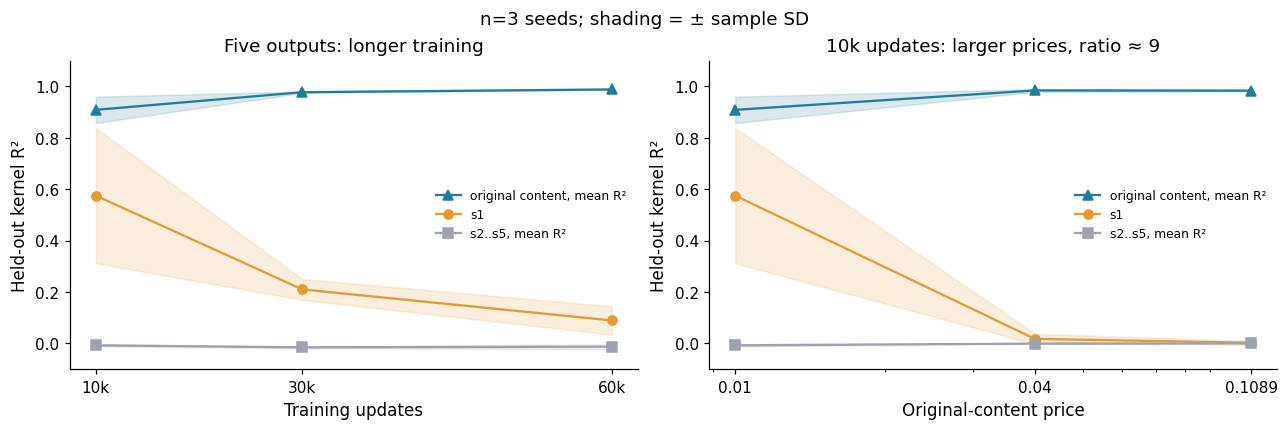

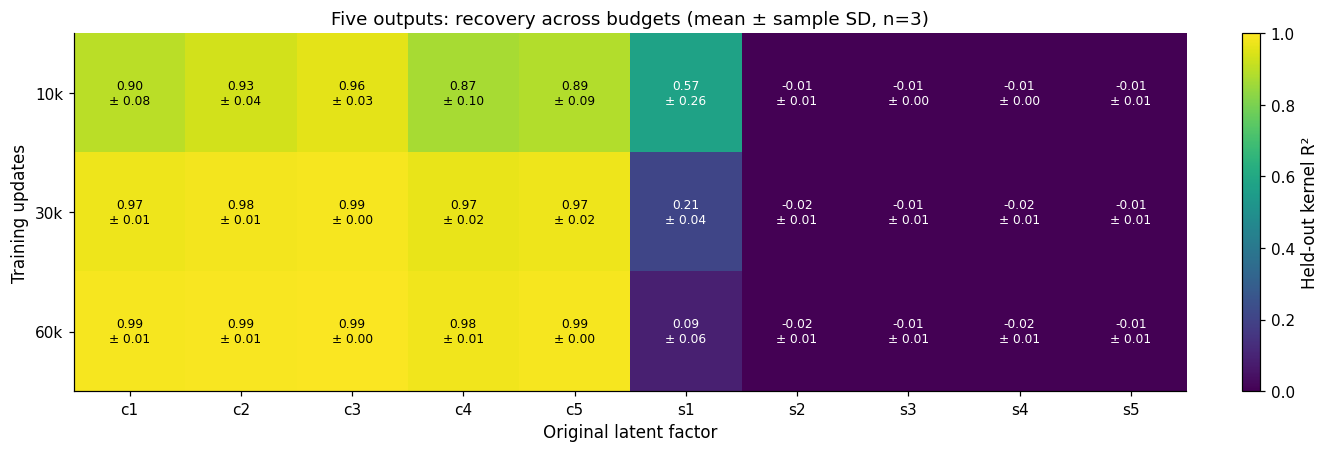

In [16]:
# CHANGED [8]: uncertainty across seeds; fixed-scale yellow/dark recovery heatmaps.
def fu_plot_comparisons(frame):
    panels = [name for name in ('budget', 'level') if name in RUN_TESTS]
    if not panels:
        return
    fig, axes = plt.subplots(1, len(panels), figsize=(5.8 * len(panels), 3.8),
                             squeeze=False, layout='constrained')
    for ax, test in zip(axes[0], panels):
        if test == 'budget':
            subset = frame[frame.test == 'budget'].copy()
            x_name = 'updates'
        else:
            baseline = frame[(frame.world == 'nongaussian') & (frame.rep_dim == NC)
                             & (frame.updates == FU_BASE_UPDATES)
                             & np.isclose(frame.content_std, .10)
                             & np.isclose(frame.s1_std, .30)
                             & frame.test.isin(['budget', 'baseline'])]
            subset = pd.concat([baseline, frame[frame.test == 'level']], ignore_index=True)
            x_name = 'price_c_nominal'
        grouped = subset.groupby(x_name)[FU_RECOVERY].agg(['mean', 'std', 'count']).sort_index()
        x = grouped.index.to_numpy(float)
        for metric, marker, colour, label in [
            ('content_mean', '^', '#227c9d', 'original content, mean R²'),
            ('s1', 'o', '#e49b32', 's1'),
            ('others_mean', 's', '#9ca3af', 's2..s5, mean R²'),
        ]:
            y = grouped[(metric, 'mean')].to_numpy(float)
            sd = grouped[(metric, 'std')].to_numpy(float)
            ax.plot(x, y, marker=marker, color=colour, label=label)
            if np.isfinite(sd).any():
                ax.fill_between(x, y - sd, y + sd, color=colour, alpha=.16)
        if test == 'budget':
            ax.set(xlabel='Training updates', title='Five outputs: longer training')
            ax.set_xticks(x, [f'{int(t)//1000}k' for t in x])
        else:
            ax.set(xscale='log', xlabel='Original-content price',
                   title='10k updates: larger prices, ratio ≈ 9')
            ax.set_xticks(x, [f'{p:g}' for p in x])
        ax.set(ylabel='Held-out kernel R²', ylim=(-.10, 1.10))
        ax.legend(frameon=False, fontsize=8)
    n_seeds = frame.seed.nunique()
    note = (f'n={n_seeds} seeds; shading = ± sample SD' if n_seeds > 1
            else 'n=1 seed; no between-seed SD')
    fig.suptitle(note, fontsize=12)
    fig.savefig(FU_DIR / 'followups.png', dpi=200)
    plt.show()
    plt.close(fig)


def fu_plot_budget_heatmap(frame):
    subset = frame[frame.test == 'budget']
    if subset.empty:
        return
    stats = subset.groupby('updates')[FU_PER_FACTOR].agg(['mean', 'std', 'count']).reindex(BUDGETS)
    values = stats.xs('mean', level=1, axis=1).to_numpy(float)
    sds = stats.xs('std', level=1, axis=1).to_numpy(float)
    counts = stats.xs('count', level=1, axis=1).to_numpy(int)
    fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')
    im = ax.imshow(values, aspect='auto', cmap='viridis', vmin=0, vmax=1)
    for i in range(len(BUDGETS)):
        for j in range(N):
            label = (f'{values[i,j]:.2f}\n± {sds[i,j]:.2f}' if counts[i,j] > 1
                     else f'{values[i,j]:.2f}')
            ax.text(j, i, label, ha='center', va='center', fontsize=8,
                    color='black' if values[i,j] >= .65 else 'white')
    ax.set_xticks(range(N), COORDS)
    ax.set_yticks(range(len(BUDGETS)), [f'{b//1000}k' for b in BUDGETS])
    n_seeds = subset.seed.nunique()
    note = (f'mean ± sample SD, n={n_seeds}' if n_seeds > 1
            else 'n=1; no between-seed SD')
    ax.set(xlabel='Original latent factor', ylabel='Training updates',
           title=f'Five outputs: recovery across budgets ({note})')
    fig.colorbar(im, ax=ax, label='Held-out kernel R²')
    fig.savefig(FU_DIR / 'budget_recovery_mean_std.png', dpi=200)
    plt.show()
    plt.close(fig)


fu_plot_comparisons(fu)
fu_plot_budget_heatmap(fu)
ng_atomic_json(FU_DIR / 'run_status.json', {
    'status': 'complete', 'plan_id': FU_PLAN_ID,
    'completed_condition_seed_rows': len(fu)})


### Interpretation reminder
These diagnostics measure predictive recovery, not a literal count of dimensions
assigned to factors. Three seeds assess repeatability over these runs; they do not
establish eventual convergence. The Gaussian reference changes both latent and
augmentation distributions. Read the absolute forward linear-fit R² together with
its kernel-minus-linear gap when assessing the composite map h = g ∘ f.
